In [1]:
import h5pyd
import h5py
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np
import haversine
from haversine import haversine, Unit
import numpy as np
from datetime import datetime

In [2]:
sites = pd.read_csv('C:/Users/sarah/Documents/GitHub/ORKA_StatusReport_FollowupPaper/StatusReport_FollowupPaper_Data/MasterSiteList_FollowupPaper.csv')
sites = sites.iloc[0:15,0:8]
sites

,Site,SiteCode,Area,AreaCode,Port,SiteLatitude,SiteLongitude,Number2023Trans_Estiamted
0,Cape Lookout,LOOK,Cape Lookout,LKOUT,Pacific City,45.336730,-123.980000,0
1,Pacific City,PACC,Cape Lookout,LKOUT,Pacific City,45.212470,-123.985186,12
2,Cape Foulweather,FOUL,Cape Foulweather,FOULW,Depoe Bay,44.784468,-124.074200,44
3,Otter Rock,OTRK,Cape Foulweather,FOULW,Depoe Bay,44.746630,-124.072591,52
4,Gregory Point,GREG,Cape Arago,ARAGO,Coos Bay,43.339313,-124.378642,10
5,Simpson Reef,SIMP,Cape Arago,ARAGO,Coos Bay,43.315740,-124.404422,16
6,Drake Point,DRAK,Cape Arago,ARAGO,Coos Bay,43.300839,-124.400720,14
7,Blanco Reef,BLCO,Cape Blanco,BLANC,Port Orford,42.831791,-124.581814,16
8,Orford Reef,ORRF,Cape Blanco,BLANC,Port Orford,42.788491,-124.595368,26
9,Port Orford Heads,ORFH,Cape Blanco,BLANC,Port Orford,42.735759,-124.507747,26


In [3]:
temp = pd.read_csv("D:/ORKA_StatusReportFollowupPaper/LO_SurfaceBrookingsAreas/processed_yearlyfiles/surface_temp_all.csv")
temp = temp.dropna()
#temp_east is 10,733,967 rows long
temp_east = pd.read_csv("D:/ORKA_StatusReportFollowupPaper/LO_SurfaceBrookingsAreas/processed_yearlyfiles/surface_temp_east_all.csv")
temp = pd.concat([temp,temp_east])
print("Number of time steps is", temp.ocean_time.nunique())
print("Lat/lon combos is", len(temp[['lon_rho','lat_rho']].drop_duplicates()))
#drop 2024 values and reset index
temp.ocean_time = pd.to_datetime(temp.ocean_time)
temp = temp.loc[temp.ocean_time < "2023-12-31"].reset_index()

Number of time steps is 4383
Lat/lon combos is 48278


In [4]:
#create a lookup table bewteen the sites and the nearest grid cell in the temperature dataset
#List of how the transect sites correspond to cells 
lat = sites.SiteLatitude[0]
lon = sites.SiteLongitude[0]
site = (lat, lon)
site_rounded = (round(lat,2), round(lon, 2))
temp_sub = temp.loc[(temp.lat_rho < site[0] +0.01) & (temp.lat_rho > site[0]-0.01)]
def hav_dist(row):
    site2 = (row["lat_rho"],row["lon_rho"])
    return haversine(site,site2)
coords_sub = temp_sub[["lon_rho","lat_rho"]].drop_duplicates()
coords_sub["dist"] = coords_sub.apply(hav_dist, axis = 1)
cell_coords = coords_sub.loc[coords_sub.dist == coords_sub.dist.min()]

for i in range(1,len(sites)): 
    print(i, "has the latitude", sites.SiteLatitude[i])
    site = (sites.SiteLatitude[i], sites.SiteLongitude[i])
    temp_sub = temp.loc[(temp.lat_rho < site[0] +0.01) & (temp.lat_rho > site[0]-0.01)]
    coords_sub = temp_sub[["lon_rho","lat_rho"]].drop_duplicates()
    coords_sub["dist"] = coords_sub.apply(hav_dist, axis = 1)
    cell_coords2 = coords_sub.loc[coords_sub.dist == coords_sub.dist.min()]
    cell_coords = pd.concat([cell_coords, cell_coords2])
    print(i," is finished, hooray!")
#then merge back with the transect list
cell_coords = cell_coords.reset_index()
sites_merged = pd.concat([sites,cell_coords[['lat_rho','lon_rho']]], axis = 1)
sites_merged

1 has the latitude 45.21247
1  is finished, hooray!
2 has the latitude 44.7844682
2  is finished, hooray!
3 has the latitude 44.74663003
3  is finished, hooray!
4 has the latitude 43.339313
4  is finished, hooray!
5 has the latitude 43.31574013
5  is finished, hooray!
6 has the latitude 43.30083932
6  is finished, hooray!
7 has the latitude 42.831791
7  is finished, hooray!
8 has the latitude 42.78849071
8  is finished, hooray!
9 has the latitude 42.73575941
9  is finished, hooray!
10 has the latitude 42.70231218
10  is finished, hooray!
11 has the latitude 42.66761529
11  is finished, hooray!
12 has the latitude 42.44372583
12  is finished, hooray!
13 has the latitude 42.065901
13  is finished, hooray!
14 has the latitude 42.042227
14  is finished, hooray!


,Site,SiteCode,Area,AreaCode,Port,SiteLatitude,SiteLongitude,Number2023Trans_Estiamted,lat_rho,lon_rho
0,Cape Lookout,LOOK,Cape Lookout,LKOUT,Pacific City,45.336730,-123.980000,0,45.335118,-123.981283
1,Pacific City,PACC,Cape Lookout,LKOUT,Pacific City,45.212470,-123.985186,12,45.213317,-123.988016
2,Cape Foulweather,FOUL,Cape Foulweather,FOULW,Depoe Bay,44.784468,-124.074200,44,44.783831,-124.077410
3,Otter Rock,OTRK,Cape Foulweather,FOULW,Depoe Bay,44.746630,-124.072591,52,44.749722,-124.070370
4,Gregory Point,GREG,Cape Arago,ARAGO,Coos Bay,43.339313,-124.378642,10,43.342748,-124.374920
5,Simpson Reef,SIMP,Cape Arago,ARAGO,Coos Bay,43.315740,-124.404422,16,43.320523,-124.408119
6,Drake Point,DRAK,Cape Arago,ARAGO,Coos Bay,43.300839,-124.400720,14,43.298217,-124.399769
7,Blanco Reef,BLCO,Cape Blanco,BLANC,Port Orford,42.831791,-124.581814,16,42.834800,-124.582252
8,Orford Reef,ORRF,Cape Blanco,BLANC,Port Orford,42.788491,-124.595368,26,42.786595,-124.591327
9,Port Orford Heads,ORFH,Cape Blanco,BLANC,Port Orford,42.735759,-124.507747,26,42.738041,-124.519727


In [5]:
%%time
#Ok calculating the haversine distances over this many columns is not happening....

lat = sites.SiteLatitude[0]
lon = sites.SiteLongitude[0]
site = (lat, lon)
site_rounded = (round(lat,2), round(lon, 2))
temp_sub = temp.loc[(temp.lat_rho < site[0] +0.01) & (temp.lat_rho > site[0]-0.01)]
def hav_dist(row):
    site2 = (row["lat_rho"],row["lon_rho"])
    return haversine(site,site2)
dist = temp_sub.apply(hav_dist, axis = 1)
index1 = dist[dist == dist.min()].index
temp_forsites = temp.iloc[index1.values[:],]

for i in range(1,len(sites)): 
    #print(i, "has the latitude", sites.SiteLatitude[i])
    site = (sites.SiteLatitude[i], sites.SiteLongitude[i])
    temp_sub = temp.loc[(temp.lat_rho < site[0] +0.01) & (temp.lat_rho > site[0]-0.01)]
    dist = temp_sub.apply(hav_dist, axis = 1)
    index1 = dist[dist == dist.min()].index
    closest = temp.iloc[index1.values[:],]
    print(i)
    print(closest.iloc[1,6])
    temp_forsites = pd.concat([temp_forsites,closest])
    print(i," is finished, hooray!")

1
45.21331748549788
1  is finished, hooray!
2
44.78383099999047
2  is finished, hooray!
3
44.74972204231666
3  is finished, hooray!
4
43.342748340363855
4  is finished, hooray!
5
43.32052277193761
5  is finished, hooray!
6
43.29821697682596
6  is finished, hooray!
7
42.83479975382984
7  is finished, hooray!
8
42.78659473126096
8  is finished, hooray!
9
42.73804107337505
9  is finished, hooray!
10
42.70139552190807
10  is finished, hooray!
11
42.66455137467071
11  is finished, hooray!
12
42.43925529923458
12  is finished, hooray!
13
42.06055447045627
13  is finished, hooray!
14
42.03370062156226
14  is finished, hooray!
CPU times: total: 4min 11s
Wall time: 3min 57s


In [6]:
#ok so first things first, find 15 degrees
# group obs of 15 deg by site and by month, transform the number of observations to the % of observations, plot on a graph where x-axis = month 
#and y-axis = % with a dot colored for each site. Not too hard
temp_forsites = temp_forsites[["ocean_time", "eta_rho","xi_rho","surf_temp", "lon_rho", "lat_rho"]].reset_index()
temp_15 = temp_forsites.loc[temp_forsites["surf_temp"]>= 15].reset_index()
temp_15["Month"] = temp_15.ocean_time.dt.month
temp_15bymonth = temp_15.groupby(["lat_rho","Month"]).Month.value_counts().reset_index()
temp_15total = temp_15.groupby("lat_rho").Month.count().reset_index()
temp_15total.columns = ["lat_rho","TotalObs"]
temp_new = temp_15bymonth.merge(temp_15total)
temp_new["MonthCountPercent"] = temp_new["count"]/temp_new["TotalObs"]*100
temp_new["lat_rho"] = temp_new["lat_rho"].round(6)
temp_new["Site"] = temp_new["lat_rho"].case_when([
    (temp_new.lat_rho == 42.033701,"Chetco Point"),
    (temp_new.lat_rho == 42.060554, "Harris Beach"),
    (temp_new.lat_rho == 42.439255, "Rogue Reef"),
    (temp_new.lat_rho == 42.664551, "Humbug"),
    (temp_new.lat_rho == 42.701396, "Redfish Rocks"),
    (temp_new.lat_rho == 42.738041, "Port Orford Heads"),
    (temp_new.lat_rho == 42.786595, "Orford Reef"),
    (temp_new.lat_rho == 42.834800, "Blanco Reef"),
    (temp_new.lat_rho == 43.298217, "Drake Point"),
    (temp_new.lat_rho == 43.320523, "Simpson Reef"),
    (temp_new.lat_rho == 43.342748, "Gregory Point"),
    (temp_new.lat_rho == 44.749722, "Otter Rock"),
    (temp_new.lat_rho == 44.783831, "Cape Foulweather"),
    (temp_new.lat_rho == 45.213317, "Pacific City"),
    (temp_new.lat_rho == 45.335118, "Cape Lookout")
]).astype("string")
#temp_new.Site = temp_new.Site.astype(str)
#remove Lookout, won't need it for this analysis
temp_new.loc[temp_new.Site != "Cape Lookout"]

,lat_rho,Month,count,TotalObs,MonthCountPercent,Site
0,42.033701,7,1,28,3.571429,Chetco Point
1,42.033701,10,14,28,50.000000,Chetco Point
2,42.033701,11,13,28,46.428571,Chetco Point
3,42.060554,10,10,23,43.478261,Harris Beach
4,42.060554,11,13,23,56.521739,Harris Beach
...,...,...,...,...,...,...
57,45.213317,6,5,73,6.849315,Pacific City
58,45.213317,7,11,73,15.068493,Pacific City
59,45.213317,8,10,73,13.698630,Pacific City
60,45.213317,9,39,73,53.424658,Pacific City


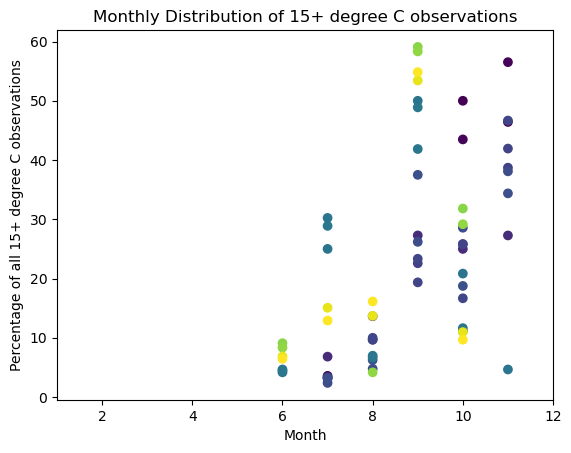

In [7]:
#have by color, would be nice to have with distinct shapes 
plt.scatter(temp_new['Month'], temp_new["MonthCountPercent"], c = temp_new["lat_rho"])
plt.xlim(1,12)
plt.xlabel('Month')
plt.ylabel('Percentage of all 15+ degree C observations')
plt.title('Monthly Distribution of 15+ degree C observations')
plt.show()

C:\Users\sarah\AppData\Local\Temp\ipykernel_4652\2666003365.py:35: UserWarning: You passed a edgecolor/edgecolors ('black') for an unfilled marker ('2').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  plt.scatter(
C:\Users\sarah\AppData\Local\Temp\ipykernel_4652\2666003365.py:35: UserWarning: You passed a edgecolor/edgecolors ('black') for an unfilled marker ('3').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  plt.scatter(
C:\Users\sarah\AppData\Local\Temp\ipykernel_4652\2666003365.py:35: UserWarning: You passed a edgecolor/edgecolors ('black') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  plt.scatter(


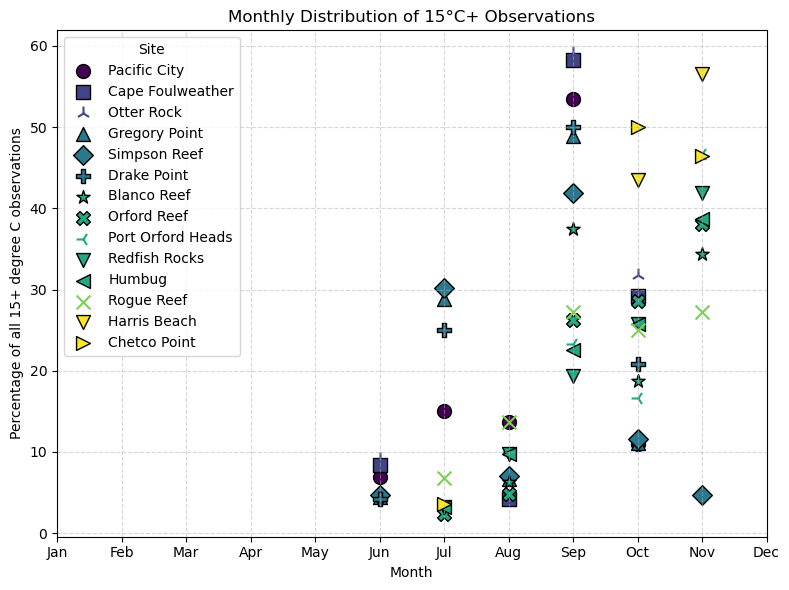

In [7]:
#Same graph as above, but with unique symbols for every site
#Will want to remove Cape Lookout as well
temp_new_sorted = temp_new.sort_values(by='lat_rho')
categories = np.array(temp_new_sorted.Site)


# Define color and marker cycles
#colors = plt.cm.tab20.colors  #need 14 distinct colors
#colors = ["orange","orange", "blue", "pink", "pink", "pink", "purple", "purple", "green", "green", "green", "yellow", "yellow", "red", "red"]
#colors = ["#332288","#332288", "#117733", "#44AA99", "#44AA99", "#44AA99", "#88CCEE", "#88CCEE", "#DDCC77", "#DDCC77", "#DDCC77", 
#          "#CC6677", "#CC6677", "#AA4499"]
#now using more viridis inspired colors
colors = ["#440154","#414487","#414487", "#2a788e", "#2a788e","#2a788e","#22a884","#22a884","#22a884","#22a884","#22a884","#7ad151","#fde725","#fde725"]

markers = ['o', 's', '2', '^', 'D', 'P', '*', 'X','3', 'v', '<', "x","v",'>',"1"]  # marker styles

# Create mapping for each category
#unique_categories = sorted(set(categories))
unique_categories = ["Chetco Point", "Harris Beach", "Rogue Reef", "Humbug","Redfish Rocks","Port Orford Heads", "Orford Reef", "Blanco Reef",
                    "Drake Point", "Simpson Reef","Gregory Point", "Otter Rock", "Cape Foulweather", "Pacific City" ]
unique_categories.reverse()
category_styles = {}
for i, cat in enumerate(unique_categories):
#for i, cat in enumerate(categories):

    category_styles[cat] = {
        'color': colors[i % len(colors)],
        'marker': markers[i % len(markers)]
    }
# Plot each category with its unique style
plt.figure(figsize=(8, 6))
for cat in unique_categories:
#for cat in categories:
    mask = categories == cat
    plt.scatter(
        temp_new_sorted['Month'][mask], temp_new_sorted["MonthCountPercent"][mask],
        color=category_styles[cat]['color'],
        marker=category_styles[cat]['marker'],
        label=f"{cat}",
        edgecolor='black',  # optional for better visibility
        s=100
    )

plt.xlim(1,12)
plt.xlabel('Month')
plt.xticks([1,2,3,4,5,6,7,8,9,10,11,12],["Jan","Feb","Mar", "Apr","May","Jun","Jul", "Aug","Sep", "Oct", "Nov","Dec"])
plt.ylabel('Percentage of all 15+ degree C observations')
plt.title('Monthly Distribution of 15\N{DEGREE SIGN}C+ Observations')
plt.legend(title="Site")
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig("C:/Users/sarah/Documents/GitHub/ORKA_StatusReport_FollowupPaper/StatusReport_FollowupPaper_Figures/HotDaySeasonality_Feb2026.jpg", dpi = 600)
plt.show()

Stuff below is where i will work on getting duration of hot days aggregated across all the sites. Skip below if you want the 
duration of hot days by site

In [7]:
#Identify the next 15+ degree day after every 15+ degree day in th dataset (only about 554 rows total)
temp_15["NextHotDay"] = temp_15.groupby('lat_rho').ocean_time.shift(-1)
temp_15["DaysSinceHot"] = (temp_15.NextHotDay - temp_15.ocean_time).dt.days 
temp_15

In [10]:
from itertools import groupby
dayslist = temp_15.DaysSinceHot.tolist()
def count_consecutive_tuples(seq):
    return [(key, sum(1 for _ in group)) for key, group in groupby(seq)]
consecutive_tup = count_consecutive_tuples(dayslist)
print(consecutive_tup)
consecutive = pd.DataFrame(consecutive_tup, columns = ["DaysBetween","TimeConsec"])
#Fixing to remove the one one instance where there were consecutive instances of non-1 values
print(len(consecutive.loc[(consecutive.TimeConsec > 1) & (consecutive.DaysBetween != 1)]))
consecutive.loc[(consecutive.TimeConsec > 1) & (consecutive.DaysBetween != 1),"TimeConsec"] = 1
print(len(consecutive.loc[(consecutive.TimeConsec > 1) & (consecutive.DaysBetween != 1)]))


[(1.0, 2), (66.0, 1), (1.0, 3), (14.0, 1), (1.0, 2), (386.0, 1), (5.0, 1), (1.0, 4), (257.0, 1), (6.0, 1), (32.0, 1), (1.0, 1), (17.0, 1), (1.0, 7), (316.0, 1), (1.0, 1), (786.0, 1), (1.0, 1), (304.0, 1), (1.0, 1), (15.0, 1), (1.0, 1), (9.0, 2), (1.0, 1), (8.0, 1), (1.0, 3), (7.0, 1), (3.0, 1), (1.0, 13), (644.0, 1), (1.0, 1), (372.0, 1), (36.0, 1), (nan, 1), (1.0, 1), (66.0, 1), (1.0, 3), (11.0, 1), (1.0, 1), (2.0, 1), (1.0, 2), (6.0, 1), (378.0, 1), (1.0, 2), (5.0, 1), (1.0, 4), (263.0, 1), (32.0, 1), (1.0, 1), (17.0, 1), (1.0, 8), (10.0, 1), (1.0, 1), (303.0, 1), (1.0, 2), (333.0, 1), (33.0, 1), (720.0, 1), (5.0, 1), (1.0, 1), (14.0, 1), (1.0, 2), (18.0, 1), (1.0, 1), (8.0, 1), (1.0, 4), (9.0, 1), (1.0, 14), (642.0, 1), (1.0, 3), (371.0, 1), (37.0, 1), (nan, 1), (1.0, 1), (475.0, 1), (1.0, 6), (1784.0, 1), (1.0, 13), (331.0, 1), (nan, 1), (1.0, 1), (475.0, 1), (1.0, 6), (1784.0, 1), (1.0, 12), (nan, 1), (1.0, 2), (475.0, 1), (1.0, 4), (262.0, 1), (1.0, 3), (29.0, 1), (1.0, 2), (17.0

In [90]:
#Ok now use these data to answer following Qs
# What is the mean/median number of days a hot event lasts
print("The mean number of days in a row is",consecutive.TimeConsec.mean())
print("The median number of days in a row is",consecutive.TimeConsec.median()) 
# How often is a hot day a standalone event (not followed by another hot day)
print("A hot day is a standalone event",len(consecutive.loc[consecutive.TimeConsec == 1])/consecutive.TimeConsec.sum() * 100)
# When hot days are followed by hot days, how long do they last on average/median
print("When hot days occur consecutively, they last a mean of ",consecutive.loc[consecutive.TimeConsec>1].TimeConsec.mean(), "days")
print("When hot days occur consecutively, they last a median of ",consecutive.loc[consecutive.TimeConsec>1].TimeConsec.median(), "days")
    

The mean number of days in a row is 2.185770750988142
The median number of days in a row is 1.0
A hot day is a standalone event 33.09222423146474
When hot days occur consecutively, they last a mean of  5.285714285714286 days
When hot days occur consecutively, they last a median of  4.0 days


Getting the duration of hot days by site

In [54]:
#Run this only if you have not created temp_15 above
#temp_15["NextHotDay"] = temp_15.groupby('lat_rho').ocean_time.shift(-1)
#temp_15["DaysSinceHot"] = (temp_15.NextHotDay - temp_15.ocean_time).dt.days 

[0,
 1,
 2,
 3,
 4,
 5,
 6,
 7,
 8,
 9,
 10,
 11,
 12,
 13,
 14,
 15,
 16,
 17,
 18,
 19,
 20,
 21,
 22,
 23,
 24,
 25,
 26,
 27,
 28,
 29,
 30,
 31,
 32,
 33,
 34,
 35,
 36,
 37,
 38,
 39,
 40,
 41,
 42,
 43,
 44,
 45,
 46,
 47,
 48,
 49,
 50,
 51,
 52,
 53,
 54,
 55,
 56,
 57,
 58,
 59,
 60,
 61,
 62,
 63,
 64,
 65,
 66,
 67,
 68,
 69,
 70,
 71,
 72,
 73,
 74,
 75,
 76,
 77,
 78,
 79,
 80,
 81,
 82,
 83,
 84,
 85,
 86,
 87,
 88,
 89,
 90,
 91,
 92,
 93,
 94,
 95,
 96,
 97,
 98,
 99,
 100,
 101,
 102,
 103,
 104,
 105,
 106,
 107,
 108,
 109,
 110,
 111,
 112,
 113,
 114,
 115,
 116,
 117,
 118,
 119,
 120,
 121,
 122,
 123,
 124,
 125,
 126,
 127,
 128,
 129,
 130,
 131,
 132,
 133,
 134,
 135,
 136,
 137,
 138,
 139,
 140,
 141,
 142,
 143,
 144,
 145,
 146,
 147,
 148,
 149,
 150,
 151,
 152,
 153,
 154,
 155,
 156,
 157,
 158,
 159,
 160,
 161,
 162,
 163,
 164,
 165,
 166,
 167,
 168,
 169,
 170,
 171,
 172,
 173,
 174,
 175,
 176,
 177,
 178,
 179,
 180,
 181,
 182,
 183,
 184,


In [15]:
temp_15_merged = pd.merge(temp_15, sites_merged, on = ["lon_rho","lat_rho"])
temp_15_merged

,level_0,index,ocean_time,eta_rho,xi_rho,surf_temp,lon_rho,lat_rho,Month,NextHotDay,DaysSinceHot,Site,SiteCode,Area,AreaCode,Port,SiteLatitude,SiteLongitude,Number2023Trans_Estiamted
0,178,179352681,2013-06-28 12:00:00,326,3,15.020286,-123.981283,45.335118,6,2013-06-29 12:00:00,1.0,Cape Lookout,LOOK,Cape Lookout,LKOUT,Pacific City,45.336730,-123.980000,0
1,179,179355130,2013-06-29 12:00:00,326,3,15.517746,-123.981283,45.335118,6,2013-06-30 12:00:00,1.0,Cape Lookout,LOOK,Cape Lookout,LKOUT,Pacific City,45.336730,-123.980000,0
2,180,179357579,2013-06-30 12:00:00,326,3,15.282151,-123.981283,45.335118,6,2013-09-04 12:00:00,66.0,Cape Lookout,LOOK,Cape Lookout,LKOUT,Pacific City,45.336730,-123.980000,0
3,246,179519213,2013-09-04 12:00:00,326,3,15.396991,-123.981283,45.335118,9,2013-09-05 12:00:00,1.0,Cape Lookout,LOOK,Cape Lookout,LKOUT,Pacific City,45.336730,-123.980000,0
4,247,179521662,2013-09-05 12:00:00,326,3,15.535478,-123.981283,45.335118,9,2013-09-06 12:00:00,1.0,Cape Lookout,LOOK,Cape Lookout,LKOUT,Pacific City,45.336730,-123.980000,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
549,55985,59114270,2016-11-13 12:00:00,2,76,15.522964,-124.294192,42.033701,11,2016-11-14 12:00:00,1.0,Chetco Point,CHET,Brookings,BROOK,Brookings,42.042227,-124.292404,12
550,55986,59160277,2016-11-14 12:00:00,2,76,15.472106,-124.294192,42.033701,11,2016-11-15 12:00:00,1.0,Chetco Point,CHET,Brookings,BROOK,Brookings,42.042227,-124.292404,12
551,55987,59206284,2016-11-15 12:00:00,2,76,15.410966,-124.294192,42.033701,11,2016-11-16 12:00:00,1.0,Chetco Point,CHET,Brookings,BROOK,Brookings,42.042227,-124.292404,12
552,55988,59252291,2016-11-16 12:00:00,2,76,15.293097,-124.294192,42.033701,11,2016-11-17 12:00:00,1.0,Chetco Point,CHET,Brookings,BROOK,Brookings,42.042227,-124.292404,12


In [57]:
#calculating these stats site by site 
sitelist = temp_15_merged.Site.drop_duplicates().tolist()
totaldays = [np.nan] * (len(sitelist)-1)
meanno = [np.nan] * (len(sitelist)-1)
medno = [np.nan] * (len(sitelist)-1)
# How often is a hot day a standalone event (not followed by another hot day)
hotstandalone = [np.nan] * (len(sitelist)-1)
# When hot days are followed by hot days, how long do they last on average/median
ifhotmean = [np.nan] * (len(sitelist)-1)
ifhotmed = [np.nan] * (len(sitelist)-1)
def count_consecutive_tuples(seq):
    return [(key, sum(1 for _ in group)) for key, group in groupby(seq)]
for i in range(1,len(sitelist)):
    temp_15_bysite = temp_15_merged.loc[temp_15_merged.Site == sitelist[i]]
    temp_15_bysite
    dayslist = temp_15_bysite.DaysSinceHot.tolist()
    totaldays[i-1] = len(dayslist)
    consecutive_tup = count_consecutive_tuples(dayslist)
    consecutive = pd.DataFrame(consecutive_tup, columns = ["DaysBetween","TimeConsec"])
    #Fixing to remove the one one instance where there were consecutive instances of non-1 values
    consecutive.loc[(consecutive.TimeConsec > 1) & (consecutive.DaysBetween != 1),"TimeConsec"] = 1
    meanno[i-1] = consecutive.TimeConsec.mean()
    medno[i-1] =  consecutive.TimeConsec.median()
    hotstandalone[i-1] = len(consecutive.loc[consecutive.TimeConsec == 1])/consecutive.TimeConsec.sum() * 100
    ifhotmean[i-1] = consecutive.loc[consecutive.TimeConsec>1].TimeConsec.mean()
    ifhotmed[i-1] = consecutive.loc[consecutive.TimeConsec>1].TimeConsec.median()
    print(str(i) + " is done. Hooray!")



1 is done. Hooray!
2 is done. Hooray!
3 is done. Hooray!
4 is done. Hooray!
5 is done. Hooray!
6 is done. Hooray!
7 is done. Hooray!
8 is done. Hooray!
9 is done. Hooray!
10 is done. Hooray!
11 is done. Hooray!
12 is done. Hooray!
13 is done. Hooray!
14 is done. Hooray!


In [60]:
#Knitting Site level stats together into a pretty dataframe
sites_duration = pd.DataFrame(sitelist[1:15], columns = ["Site"])
sites_duration["Total15DegDays"] = totaldays
sites_duration["MeanDaysLasting"] = meanno
sites_duration["MedDaysLasting"] = medno
sites_duration["Percentof1daystreaks"] = hotstandalone
sites_duration["WhenAStreakMean"] = ifhotmean
sites_duration["WhenAStreakMed"] = ifhotmed
sites_duration
sites_duration.to_csv('C:/Users/sarah/Documents/GitHub/ORKA_StatusReport_FollowupPaper/StatusReport_FollowupPaper_Figures/SummaryStats_HotDayDuration.csv')